In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


In [2]:
import warnings
warnings.filterwarnings('ignore')

# Load the data check sample Statistics

In [3]:
df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')


**Shape of the data (rows, columns)**

In [4]:
df.shape, test_df.shape

((138701, 50), (15000, 49))

In [5]:
df.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,...,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


# Perform Exploratory Data Analysis (EDA) on the Data
### Check datatype 

In [6]:
df.dtypes

TransactionID                  int64
TargetValue                  float64
AssetID                        int64
ProductConfigID                int64
DataOriginCode                object
VendorPartnerID               object
ManufactureYear                int64
OperationalHoursMeter        float64
UtilizationTier               object
TransactionDate               object
Spec_FullDescriptor           object
Spec_BaseClass                object
Spec_SubClass                 object
Spec_ReleaseSeries            object
Spec_VariantModifier          object
AssetScaleFactor              object
FunctionalClassification      object
RegionCode                    object
InventoryGroupCategory        object
InventoryGroupDescription     object
col1                          object
CabinType                     object
Forks                         object
col3                          object
col4                          object
DrivetrainType                object
col5                          object
c

### Check null  values in columns or not

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32

In [8]:
print('Column Name                No. of Null Values')
df.isnull().sum()

Column Name                No. of Null Values


TransactionID                     0
TargetValue                       0
AssetID                           0
ProductConfigID                   0
DataOriginCode                    0
VendorPartnerID                   0
ManufactureYear                   0
OperationalHoursMeter         56643
UtilizationTier               88226
TransactionDate                   0
Spec_FullDescriptor               0
Spec_BaseClass                    0
Spec_SubClass                 36985
Spec_ReleaseSeries           105805
Spec_VariantModifier          86369
AssetScaleFactor              41210
FunctionalClassification          0
RegionCode                        0
InventoryGroupCategory            0
InventoryGroupDescription         0
col1                         104915
CabinType                         0
Forks                        109382
col3                         109448
col4                         128320
DrivetrainType                89956
col5                         128320
col6                        

In [9]:
categorical_col = df.select_dtypes('object')
numerical_col  = df.select_dtypes(['int','float'])
categorical_col.shape, numerical_col.shape

((138701, 44), (138701, 6))

## About column
There is 44 numerical and 6 categorical column present in the dataset

**TagetValue** column data type is continuous numerical variable

**TransactionDate** column containing date of transaction that is categorical variable

### Descriptive Statistics of numerical columns

In [10]:
df.describe()

,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,1.387010e+05,138701.000000,1.387010e+05,138701.000000,138701.000000,8.205800e+04
mean,2.186276e+06,41521.874047,1.204814e+06,7286.421922,1891.640853,4.553719e+03
std,1.128497e+06,26361.125948,5.287376e+05,7542.421537,306.992001,2.792204e+04
min,1.139309e+06,7500.000000,8.000000e+00,39.000000,1001.000000,0.000000e+00
25%,1.465754e+06,20500.000000,1.007930e+06,1693.000000,1990.000000,0.000000e+00
50%,1.751884e+06,35000.000000,1.246956e+06,3852.000000,1998.000000,1.620000e+03
75%,2.372139e+06,57000.000000,1.495817e+06,11873.000000,2004.000000,5.001000e+03
max,6.333410e+06,142000.000000,2.478476e+06,37209.000000,2015.000000,1.729600e+06


### Correlation matrix of Numerical Variable

In [11]:
corr  = df.select_dtypes(['int','float']).corr()
corr



,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
TransactionID,1.000000,-0.012093,0.373844,0.129477,0.065617,0.008129
TargetValue,-0.012093,1.000000,-0.238719,0.057265,0.204439,0.001994
AssetID,0.373844,-0.238719,1.000000,0.154943,-0.029941,0.003505
ProductConfigID,0.129477,0.057265,0.154943,1.000000,-0.009438,-0.013551
ManufactureYear,0.065617,0.204439,-0.029941,-0.009438,1.000000,-0.008256
OperationalHoursMeter,0.008129,0.001994,0.003505,-0.013551,-0.008256,1.000000


**"AssetID"** column highly negative corelated with 'TargetValue' compare to other

**"ManufactureYear"** column highly positive corelated with 'TargetValue compare to other

### Column contain more then 70% null values

Impute null values is not useful for this columns because **insufficient original information** it will **inroduce bias** and **reduces variability**

In [12]:
null_ = (df.isnull().sum()*100)/df.shape[0]
null_[null_>70]


Spec_ReleaseSeries    76.282795
col1                  75.641127
Forks                 78.861724
col3                  78.909309
col4                  92.515555
col5                  92.515555
col6                  83.125572
col7                  83.125572
col8                  83.125572
col9                  83.125572
col11                 83.125572
col12                 72.340502
col13                 83.125572
col14                 83.125572
col18                 99.952416
col19                 99.952416
col27                 89.214930
col28                 89.214930
col29                 86.393753
col30                 86.393753
dtype: float64

### Check any Duplicate rows present or not

In [13]:
df.duplicated().sum()

np.int64(0)

# Data Visualization

In [14]:
# library for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

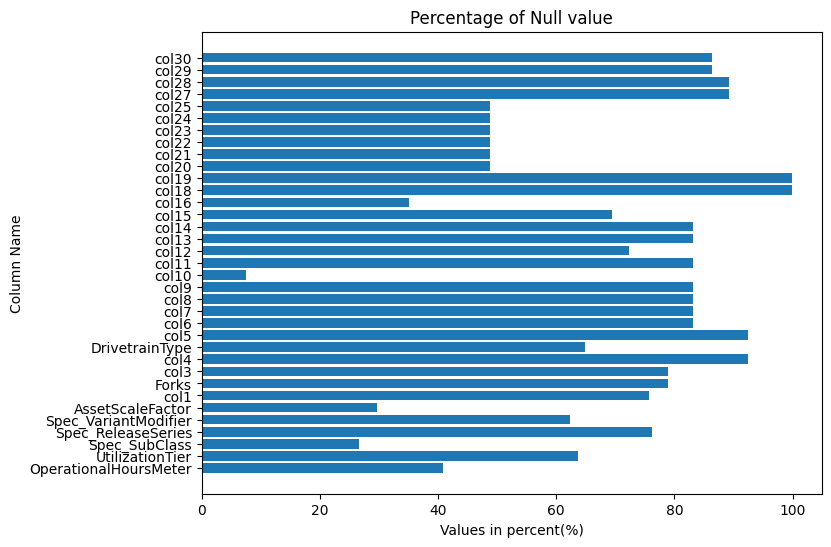

In [15]:
missing = null_[null_ > 0]
plt.figure(figsize=(8,6))
plt.barh(missing.index,missing.values)
plt.xticks(rotation=0)
plt.title("Percentage of Null value")
plt.xlabel('Values in percent(%)')
plt.ylabel("Column Name")
plt.show()

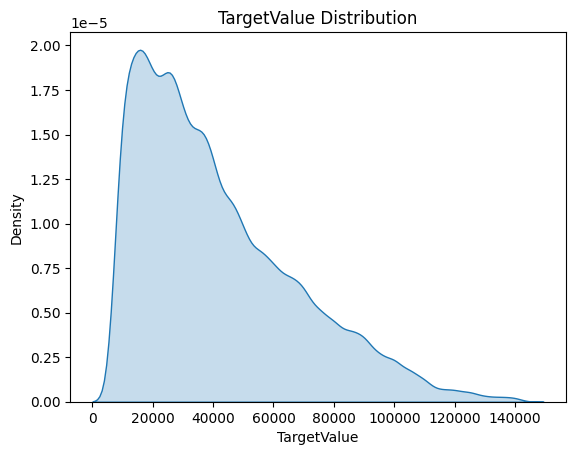

In [16]:
sns.kdeplot(df['TargetValue'], fill= True)
plt.title("TargetValue Distribution")
plt.show()

Text(0.5, 1.0, 'TargetValue vs AssetID')

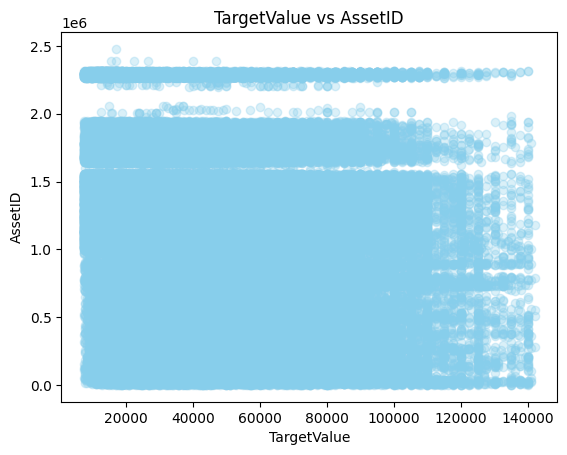

In [17]:
plt.scatter(df['TargetValue'], df['AssetID'], color="skyblue", alpha= 0.3)
plt.xlabel("TargetValue")
plt.ylabel("AssetID")
plt.title('TargetValue vs AssetID')

Text(0.5, 1.0, 'OperationalHoursMeter Distribution')

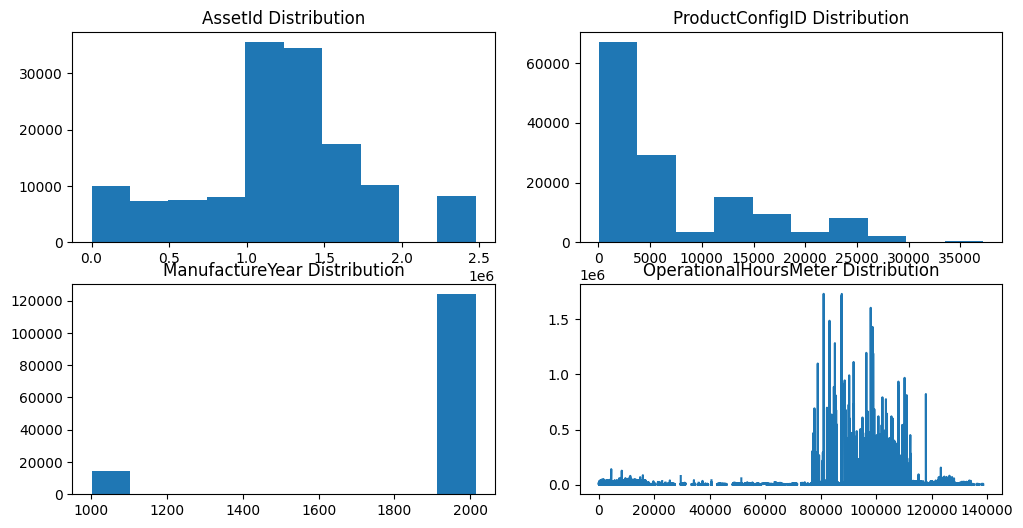

In [18]:
fig, ax =  plt.subplots(2,2, figsize=(12,6))
ax[0,0].hist(df['AssetID']) 
ax[0,0].set_title('AssetId Distribution')
ax[0,1].hist(df['ProductConfigID']) 
ax[0,1].set_title('ProductConfigID Distribution')
ax[1,0].hist(df['ManufactureYear']) 
ax[1,0].set_title('ManufactureYear Distribution')
ax[1,1].plot(df['OperationalHoursMeter']) 
ax[1,1].set_title('OperationalHoursMeter Distribution')


<Axes: >

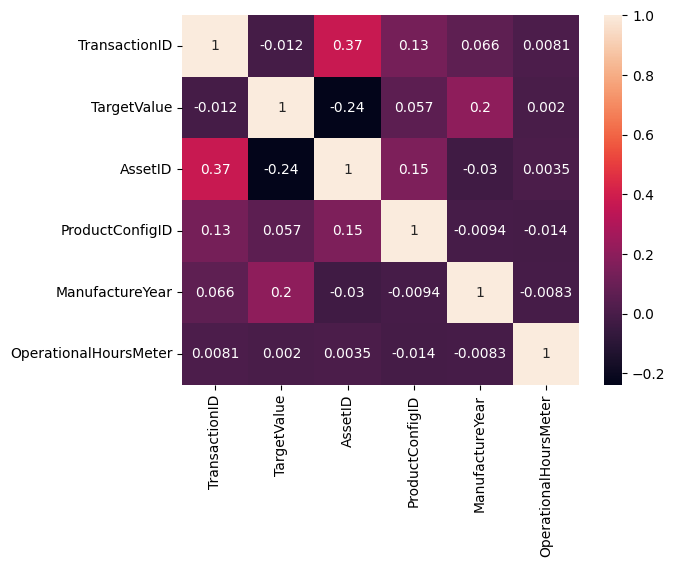

In [19]:
sns.heatmap(corr, annot=True)

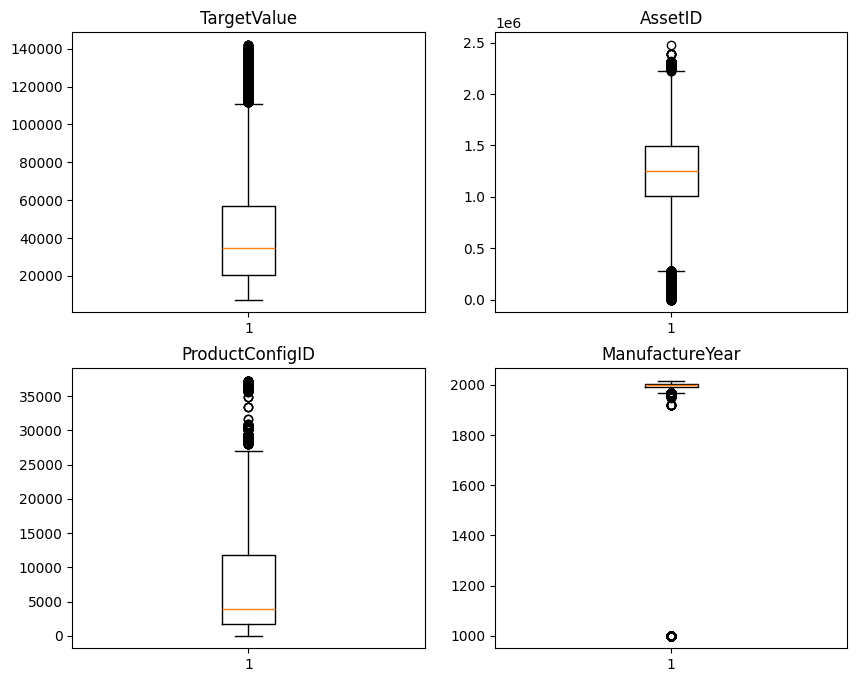

In [20]:
num_col = df.select_dtypes(['int','float'])
fig, ax = plt.subplots(2,2, figsize=(10,8))
ax[0,0].boxplot(num_col['TargetValue'])
ax[0,0].set_title("TargetValue")
ax[0,1].boxplot(num_col['AssetID'])
ax[0,1].set_title("AssetID")
ax[1,0].boxplot(num_col['ProductConfigID'])
ax[1,0].set_title('ProductConfigID')
ax[1,1].boxplot(num_col['ManufactureYear'])
ax[1,1].set_title("ManufactureYear")
plt.show()


All this columns containing several outliers and every column contain different scale

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_squared_log_error, make_scorer, r2_score
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.tree import DecisionTreeRegressor

# Feature Extraction & Preprocessing

**Important library**

**TransactionDate** dtype is object fist we convert it in datetime then extract useful features from it

In [22]:
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])
test_df['TransactionDate'] = pd.to_datetime(test_df['TransactionDate'])

In [23]:
df['TransactionYear' ] = df['TransactionDate'].dt.year
df['TransactionQuarter' ] = df['TransactionDate'].dt.quarter
df['TransactionMonth'] = df['TransactionDate'].dt.month
df["ManufactureDecade"] = np.where(df["ManufactureYear"].notna(),(df["ManufactureYear"] // 10) * 10,np.nan)
df['SpecificationComplexity'] = (df["Spec_FullDescriptor"].fillna("").str.split().str.len())

# added combined featuress
df['AssetAge'] = df['TransactionYear']-df['ManufactureYear']
df['DescriptorLength'] = df['Spec_FullDescriptor'].str.len()

# test df
test_df['TransactionYear' ] = test_df['TransactionDate'].dt.year
test_df['TransactionQuarter' ] = test_df['TransactionDate'].dt.quarter
test_df['TransactionMonth'] = test_df['TransactionDate'].dt.month
test_df["ManufactureDecade"] = np.where(test_df["ManufactureYear"].notna(),(test_df["ManufactureYear"] // 10) * 10,np.nan)
test_df['SpecificationComplexity'] = (test_df["Spec_FullDescriptor"].fillna("").str.split().str.len())

# added combined featuress
test_df['AssetAge'] = test_df['TransactionYear']-test_df['ManufactureYear']
test_df['DescriptorLength'] = test_df['Spec_FullDescriptor'].str.len()

#### Row feature selected those contain less amount of null values 

In [24]:
train_df = df.drop(columns=[ 'TransactionID','AssetID'])
int_col = train_df.select_dtypes(['int','float']).columns.to_list()
selected_col = int_col + ['DataOriginCode','VendorPartnerID','UtilizationTier','AssetScaleFactor','RegionCode','InventoryGroupCategory','InventoryGroupDescription','CabinType',  "Spec_FullDescriptor", "Spec_BaseClass",'FunctionalClassification','col21'] #+ col10 it err+ 
train_df = train_df[selected_col]
# print(int_col)
print(train_df.shape)

(138701, 23)


**Data split** in **80/20** where 80% for training and 20% for validation with random state 42

In [25]:
X_train, X_valid, y_train, y_valid = train_test_split(
    train_df.drop(columns=['TargetValue']),
    train_df['TargetValue'],
    test_size=0.2,
    random_state=42
)

In [26]:
# for submission only
X_train = train_df.drop(columns=['TargetValue'])
y_train = train_df['TargetValue']

In [27]:
X_test = test_df[X_train.columns]
X_train.shape, X_test.shape

((138701, 22), (15000, 22))

Some statical feature added by grouping ProductConfigID with TargetValue like mean, madian, min, max, standard deviation

In [28]:
state = (
    train_df.groupby("ProductConfigID")["TargetValue"].agg( 
        mean="mean",
        median="median",
        min="min",
        max="max",
        std="std",
        count="count",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75))
)
state["iqr"] = state["q25"] - state["q75"]

X_train["ProductConfigID_mean"] = (
    X_train["ProductConfigID"].map(state['mean'])
)
X_train["ProductConfigID_median"] = (
    X_train["ProductConfigID"].map(state['median'])
)
X_train["ProductConfigID_std"] = (
    X_train["ProductConfigID"].map(state['std'])
)
X_train["ProductConfigID_min"] = (
    X_train["ProductConfigID"].map(state['min'])
)
X_train["ProductConfigID_max"] = (
    X_train["ProductConfigID"].map(state['max'])
)


# validation maping
X_valid["ProductConfigID_mean"] = (
    X_valid["ProductConfigID"].map(state['mean'])
)
X_valid["ProductConfigID_median"] = (
    X_valid["ProductConfigID"].map(state['median'])
)
X_valid["ProductConfigID_std"] = (
    X_valid["ProductConfigID"].map(state['std'])
)
X_valid["ProductConfigID_min"] = (
    X_valid["ProductConfigID"].map(state['min'])
)
X_valid["ProductConfigID_max"] = (
    X_valid["ProductConfigID"].map(state['max'])
)


X_test["ProductConfigID_mean"] = (
    X_test["ProductConfigID"].map(state['mean'])
)
X_test["ProductConfigID_median"] = (
    X_test["ProductConfigID"].map(state['median'])
)
X_test["ProductConfigID_std"] = (
    X_test["ProductConfigID"].map(state['std'])
)
X_test["ProductConfigID_min"] = (
    X_test["ProductConfigID"].map(state['min'])
)
X_test["ProductConfigID_max"] = (
    X_test["ProductConfigID"].map(state['max'])
)


In [29]:
X_train.shape, X_test.shape

((138701, 27), (15000, 27))

Some statical feature added by grouping UtilizationTier with TargetValue like mean, madian, standard deviation, count

In [30]:
state = (
    train_df.groupby("UtilizationTier")["TargetValue"].agg( 
        mean="mean",
        median="median",
        std="std",
        count="count"
    )
)

X_train["UtilizationTier_mean"] = (
    X_train["UtilizationTier"].map(state['mean'])
)
X_train["UtilizationTier_median"] = (
    X_train["UtilizationTier"].map(state['median'])
)

X_train["UtilizationTier_count"] = (
    X_train["UtilizationTier"].map(state['count'])
)



# validation maping
X_valid["UtilizationTier_mean"] = (
    X_valid["UtilizationTier"].map(state['mean'])
)
X_valid["UtilizationTier_median"] = (
    X_valid["UtilizationTier"].map(state['median'])
)

X_valid["UtilizationTier_count"] = (
    X_valid["UtilizationTier"].map(state['count'])
)



X_test["UtilizationTier_mean"] = (
    X_test["UtilizationTier"].map(state['mean'])
)
X_test["UtilizationTier_median"] = (
    X_test["UtilizationTier"].map(state['median'])
)

X_test["UtilizationTier_count"] = (
    X_test["UtilizationTier"].map(state['count'])
)


#### Frequency encoding of categorical columns

In [31]:
new_list = ['DataOriginCode', 'VendorPartnerID', 'UtilizationTier',
       'AssetScaleFactor', 'RegionCode', 'InventoryGroupCategory',
       'InventoryGroupDescription', 'CabinType', 'Spec_FullDescriptor',
       'Spec_BaseClass', 'FunctionalClassification', 'col21']
for col in new_list:
    freq = X_train[col].value_counts(normalize=True)

    X_train[col+"_freq"] = X_train[col].map(freq).fillna(0)
    X_valid[col+"_freq"] = X_valid[col].map(freq).fillna(0)
    X_test[col+"_freq"] = X_test[col].map(freq).fillna(0)
# add this features with freq_encoding

In [32]:
X_test.shape, X_train.shape

((15000, 42), (138701, 42))

#### Target encoding for categorical column

In [33]:
def target_encode(train_col, valid_col, test_col , y_train, smoothing=5):

    temp = pd.DataFrame({
        "category": train_col,
        "target": y_train
    })

    stats = temp.groupby("category")["target"].agg(
        ["mean", "count"]
    )

    global_mean = y_train.mean()

    smoothing_factor = (
        stats["count"] /
        (stats["count"] + smoothing)
    )

    stats["encoding"] = (
        smoothing_factor * stats["mean"]
        + (1 - smoothing_factor) * global_mean
    )

    train_encoded = train_col.map(stats["encoding"]).fillna(global_mean)
    valid_encoded = valid_col.map(stats["encoding"]).fillna(global_mean)
    test_encoded = test_col.map(stats["encoding"]).fillna(global_mean)

    return train_encoded, valid_encoded, test_encoded


for x in new_list:
  X_train[x+'_tg'], X_valid[x+'_tg'], X_test[x+"_tg"]= target_encode(X_train[x],X_valid[x],X_test[x], y_train)


In [34]:
X_train.shape, X_test.shape

((138701, 54), (15000, 54))

#### Drop highy cardinality categorical column

In [35]:
X_train = X_train.drop(columns=['Spec_FullDescriptor','Spec_BaseClass','FunctionalClassification','col21'])
X_valid = X_valid.drop(columns=['Spec_FullDescriptor','Spec_BaseClass','FunctionalClassification','col21'])
X_test = X_test.drop(columns=['Spec_FullDescriptor','Spec_BaseClass','FunctionalClassification','col21'])
X_train.shape, X_valid.shape, X_test.shape

((138701, 50), (27741, 50), (15000, 50))

## Preprocessing Pipeline
**Categorical Column -** impute with mode and encode by OneHotEncoding 

**Numerical Column -** impute with median and scale by StandardScaler

In [36]:
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy= "most_frequent")),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # change strategy median to mean
    ('scaler', StandardScaler())
])


prossesor = ColumnTransformer(
    transformers =[
      ('cat', cat_pipeline, make_column_selector(dtype_include=object)),
      ('num', num_pipeline, make_column_selector(dtype_include=np.number))
    ],
    # remainder="drop"
)

In [37]:
prossesor.set_output(transform="pandas")
X_train_proc = prossesor.fit_transform(X_train)
X_valid_proc = prossesor.transform(X_valid)
X_test_proc = prossesor.transform(X_test)
X_train_proc.shape, X_valid_proc.shape
# X_test_proc.shape

((138701, 156), (27741, 156))

Text(0.5, 1.0, 'Target with Natural Log')

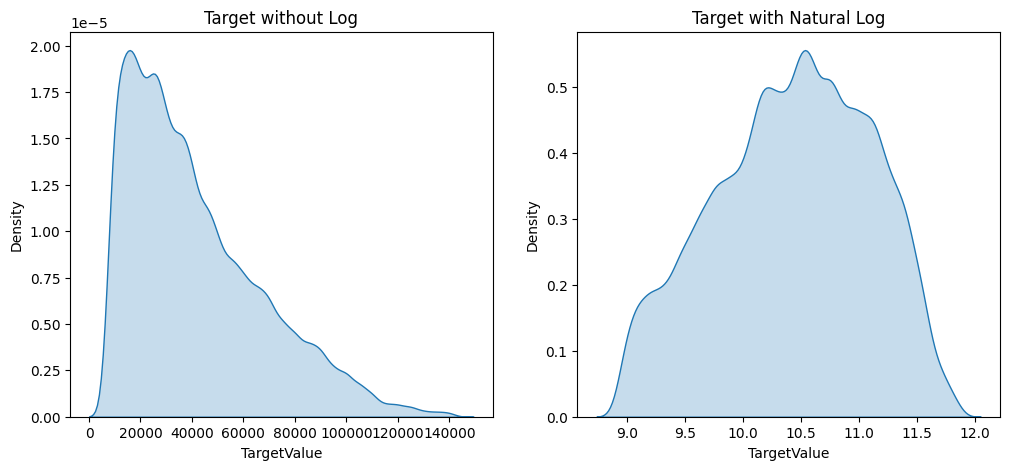

In [38]:
fig, ax = plt.subplots(1,2,figsize=(12, 5))
sns.kdeplot(y_train, fill= True, ax=ax[0])
ax[0].set_title("Target without Log")
sns.kdeplot(np.log1p(y_train), fill=True, ax= ax[1])
ax[1].set_title("Target with Natural Log")

**TargetValue** is strongly **right-skewed**. Therefore, training on log1p(TargetValue) reduces the influence of extreme transactions and aligns naturally with the RMSLE metric.

In [39]:
selector = SelectKBest(score_func=f_regression, k=130)
X_train_selected = selector.fit_transform(X_train_proc, y_train)
X_valid_selected = selector.transform(X_valid_proc)

feature_names = selector.get_feature_names_out()

feature_scores = pd.DataFrame({
    "Feature": X_train_proc.columns,
    "F_score": selector.scores_,
    "P_value": selector.pvalues_
})

feature_scores[selector.get_support()].sort_values('F_score', ascending=False)[:10]

,Feature,F_score,P_value
124,num__ProductConfigID_mean,345982.158999,0.0
125,num__ProductConfigID_median,332943.303959,0.0
152,num__Spec_FullDescriptor_tg,317927.527822,0.0
128,num__ProductConfigID_max,147610.205897,0.0
127,num__ProductConfigID_min,104595.455101,0.0
153,num__Spec_BaseClass_tg,103652.535168,0.0
126,num__ProductConfigID_std,81540.489249,0.0
154,num__FunctionalClassification_tg,75461.662861,0.0
151,num__CabinType_tg,33264.479318,0.0
112,cat__CabinType_EROPS w AC,33264.152789,0.0


**SelectKBest** was evaluated using F-statistics with k=130. Reducing the feature space below the current representation consistently degraded RMSLE. This suggests that several lower-ranked features provide complementary nonlinear information that is not captured by univariate F-statistics. Therefore, feature selection was not applied to the final model

In [40]:
y_train_log = np.log1p(y_train)
rd_forest = RandomForestRegressor(
  n_estimators= 500,
  min_samples_split= 5,
  min_samples_leaf= 1,
  max_features= 0.5,
  max_depth= None,
  n_jobs=-1,
  random_state=42)
# rd_forest.fit(X_train_proc, y_train_log)

In [41]:
# pred_log = rd_forest.predict(X_valid_proc)
# pred = np.expm1(pred_log)
# mean_squared_log_error(y_valid, pred), mean_squared_error(y_valid, pred)

**RandomForest Model Performance :-**
* **MSLE** - 0.03985043801376848, 
* **MSE** - 64124976.67342897
* **RMSLE** - 0.199625744
* **Train R2 Score** - 0.979653
* **Test R2 Score** - 0.906137

In [42]:
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 15, 25, 35],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": [0.5, 0.7, 1.0]
}
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

rd_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_log_error",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)
# rd_search.fit(X_train_selected, y_train_log)

In [43]:
# rd_search.best_params_, rd_search.best_score_

**Best parameter** after fitting is :-

* 'n_estimators': 500,
* 'min_samples_split': 5,
* 'min_samples_leaf': 1,
* 'max_features': 0.5,
* 'max_depth': None,

 **Best Score -** np.float64(-0.021461876426555657))

In [44]:
import lightgbm as lgb

In [45]:
temp_modal = lgb.LGBMRegressor(
   objective="regression",
    n_estimators=5000,
    learning_rate=0.05,
    num_leaves=100,
    max_depth=-1,
    subsample=0.8,
    min_child_samples=120,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=0.0,
    random_state=42,
    n_jobs=-1
)
temp_modal.fit(
    X_train_proc,
    np.log1p(y_train),
    eval_set=[(
        X_valid_proc, 
        np.log1p(y_valid))],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=150,
            verbose=True
        )
    ]
  )

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021829 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3335
[LightGBM] [Info] Number of data points in the train set: 138701, number of used features: 147
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Start training from score 10.424111
Training until validation scores don't improve for 150 rounds
Did not meet early stopping. Best iteration is:
[5000]	valid_0's l2: 0.0127228


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.05, min_child_samples=120,
              n_estimators=5000, n_jobs=-1, num_leaves=100,
              objective='regression', random_state=42, subsample=0.8)

In [46]:
gbm_Pred = temp_modal.predict(X_valid_proc)
gbm_pred = np.expm1(gbm_Pred)
# gbm_pred = np.maximum(gbm_pred, 0)
gbm_mse = mean_squared_error(y_valid, gbm_pred)
gbm_msle = mean_squared_log_error(y_valid, gbm_pred)
gbm_mse, gbm_msle

(21896661.209257025, 0.01272277145984639)

**LGBM Model Performance :-**
* **MSE** = 58522958.62590644
* **MSLE** = 0.037403927727
* **RMSLE** = 0.193400950687
* **Train R2 Score** = 0.95631696
* **Valid R2 Score** = 0.91459738


In [47]:
def rmsle_scorer(y_true_log, y_pred_log):

    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)

    y_pred = np.maximum(y_pred, 0)

    return np.sqrt(
        mean_squared_log_error(
            y_true,
            y_pred
        )
    )
scorer = make_scorer(
    rmsle_scorer,
    greater_is_better=False
)
param_grid = {
    "num_leaves": [15, 31, 50, 70, 100],
    "learning_rate": [0.01, 0.03, 0.05,0.07],
    "min_child_samples": [10, 20, 50, 100,130],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [0, 0.1, 1, 5]
}

rd_search2 = RandomizedSearchCV(
    estimator=temp_modal,
    param_distributions=param_grid,
    n_iter=20,
    scoring=scorer,
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1,
)
# rd_search2.fit(X_train_proc,np.log1p(y_train))

In [48]:
# rd_search2.best_estimator_

Best Estimator return:- 
* colsample_bytree = 0.8, 
* learning_rate = 0.05, 
* n_estimators = 1000,
* n_jobs = -1, 
* num_leaves = 100, 
* objective = 'regression',
* random_state = 42, 
* reg_alpha = 0, 
* reg_lambda = 5, 
* subsample = 0.8

In [49]:
X_train_proc.shape, X_valid_proc.shape

((138701, 156), (27741, 156))

In [50]:
from xgboost import XGBRegressor

In [51]:
xgb_modal = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.02,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=10,
    reg_alpha=0.1,
    reg_lambda=2,
    random_state=42
)
xgb_modal.fit(X_train_proc, np.log1p(y_train))

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.02, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=10,
             max_leaves=None, min_child_weight=10, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=4000,
             n_jobs=None, num_parallel_tree=None, ...)

In [52]:
pred_log = xgb_modal.predict(X_valid_proc)
pred = np.expm1(pred_log)
mean_squared_log_error(y_valid, pred), mean_squared_error(y_valid, pred)

(0.008789828853906414, 16281385.897915073)

In [53]:
r2_score(y_valid, pred)


0.976240555480213

**XGBoost Model Performance :-** 
* **MSE** = 57194263.17718669
* **MSLE** = 0.0368855419304
* **RMSLE** = 0.1920560855583
* **Train R2 Score** = 0.97885808
* **Valid R2 Score** = 0.9165363482

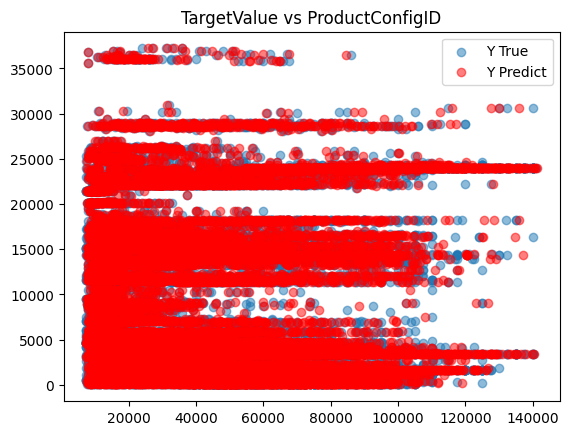

In [54]:
plt.scatter(y_valid, X_valid['ProductConfigID'],label='Y True', alpha=0.5)
plt.scatter(pred, X_valid['ProductConfigID'],label='Y Predict', color='red', alpha=0.5)
plt.legend()
plt.title("TargetValue vs ProductConfigID")
plt.show()

### Model Comparison
| Metrics | RandomForest | LightGBM | XGBoost |
|---------|--------------|----------|---------|
| MSE |64124976.6734|58522958.6259|57194263.1771|
| MSLE |0.0398|0.0374| 0.03688|
| RMSLE |0.1996|0.1934|0.1920|
| Test R2 Score |0.9796|0.9145|0.9165|
| Train R2 Score |0.9061|0.9563|0.9788|

## Final Prediction and Submission

In [55]:
log_prediction = xgb_modal.predict(X_test_proc)
prediction = np.expm1(log_prediction)
len(prediction)

15000

In [56]:
data = []
for i in range(len(prediction)):
    data.append([test_df["TransactionID"][i],prediction[i]])

In [57]:
submission_df = pd.DataFrame(data, columns = ['TransactionID',"TargetValue"])
submission_df.shape, submission_df.head(2)

((15000, 2),
    TransactionID   TargetValue
 0        1139307  63682.683594
 1        1139419  78710.406250)

In [58]:
submission_df.to_csv('submission.csv', index=False)